# 32 — Détection temporelle ReLUT

Applique le modèle ReLUT *ParkingSearchPrediction* aux segments voiture préparés par l'étape 01 (`prepared_relut_points.parquet`), **restreints aux legs du corpus commun** (`legs/corpus_by_leg.parquet`, mêmes legs que la méthode spatiale), puis :

1. histogrammes des durées de recherche prédites — ensemble des segments, participants sans et avec besoin de chercher (questionnaire PL23) ;
2. tableaux n_segments / temps moyen / temps médian (affichés et exportés en CSV) ;
3. courbes de probabilité d'un échantillon générique de segments, partie en cruising surlignée en rouge pastel ;
4. cartes : les N recherches les plus longues, un échantillon « besoin de chercher », un échantillon « pas besoin de chercher », et l'échantillon générique des courbes ;
5. table par leg `legs/relut_by_leg.parquet` (une ligne par leg, clé `leg_id`) pour la collection interopérable.

Logique : `src/parking_search_prediction/relut_detection.py`. Ligne de commande : `python scripts/32_temporal_detection.py --max-legs 300`.

In [11]:
CONFIG_NAME = "full_waypoints.yaml"
OUTPUT_DIR = "outputs/pl23"          # sorties de l'étape 01 ; "outputs/declic" pour la rétrocompatibilité

MAX_LEGS = None                       # None = toutes les legs ; sinon tirage aléatoire de MAX_LEGS legs
RANDOM_SEED = 42                     # tirage des legs et des échantillons cartographiés

P_SEARCH = "auto"                    # "auto" (seuils ReLUT selon l'échantillonnage) ou une valeur entre 0 et 1
MAX_SEARCH_DURATION_MINUTES = 15     # recherche limitée aux 15 dernières minutes ; None pour ne pas plafonner

# Groupes « besoin de chercher » (pl23) : variable du questionnaire et catégories de chaque groupe
USE_SURVEY = True                    # False pour declic (pas de questionnaire)
PARKING_VARIABLE = "space_home"      # "space_home" (domicile) ou "space_work" (travail / études)
NO_CRUISE_CATEGORIES = ["Pas de place dédiée, pas besoin de cruise"]   # ajouter "Place dédiée" pour l'inclure
CRUISE_CATEGORIES = ["Pas de place dédiée, besoin de cruise"]
USER_ID_MAP_FILE = "Data/GPS/pl23/20241120_dump_situee/241120_user_statistics.csv"
SURVEY_FILE = "Data/GPS/pl23/EPFL_vague1_v4.csv"

# Les legs traitées sont celles du corpus commun (legs/corpus_by_leg.parquet, filtres `leg_filters`
# du YAML, construit à l'étape 01) : exactement les mêmes que pour la méthode spatiale (notebook 22).

N_LONGEST_MAP = 20                   # carte des N recherches prédites les plus longues
N_SAMPLE_MAP = 20                    # taille des échantillons « besoin » / « pas besoin »
N_GENERIC_SAMPLE = 12                # courbes de probabilité + carte « generic sample » (segments tirés au hasard)
WRITE_LEG_TABLE = True               # legs/relut_by_leg.parquet ; avec MAX_LEGS : legs/_samples/<run_id>/

In [12]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import HTML, Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from parking_search_prediction.config import load_config
from parking_search_prediction.leg_collection import load_leg_table
from parking_search_prediction.relut_detection import run_temporal_detection

config = load_config(PROJECT_ROOT / "config" / CONFIG_NAME)
config["paths"]["output_dir"] = OUTPUT_DIR
config["model"].update({"p_search": P_SEARCH, "max_search_duration_minutes": MAX_SEARCH_DURATION_MINUTES})
config["temporal_detection"].update(
    {
        "max_legs": MAX_LEGS,
        "random_seed": RANDOM_SEED,
        "use_survey": USE_SURVEY,
        "parking_variable": PARKING_VARIABLE,
        "no_cruise_categories": NO_CRUISE_CATEGORIES,
        "cruise_categories": CRUISE_CATEGORIES,
        "n_longest_map": N_LONGEST_MAP,
        "n_sample_map": N_SAMPLE_MAP,
        "n_generic_sample": N_GENERIC_SAMPLE,
        "write_leg_table": WRITE_LEG_TABLE,
    }
)
config["leg_matching"]["user_id_map"] = (
    {"file": USER_ID_MAP_FILE, "legs_id_col": "user_id_fors", "waypoints_id_col": "user_id_motiontag"} if USE_SURVEY else None
)
config.setdefault("pl23_survey", {})["survey_file"] = SURVEY_FILE

In [13]:
result = run_temporal_detection(config)
display(pd.Series(result["summary"]["loop_filter"], name="corpus commun"))
pd.Series({k: v for k, v in result["summary"].items() if not isinstance(v, dict)}, name="run")

[relut] corpus commun : 55083 legs — 55351 segments sur 73921 préparés
[relut] 55'351 segments sur 55'351 (toutes les legs) — 29'836'696 points


/Users/maximiliantrique/Documents/Projet_python/parking_search_prediction _livrable_new/src/parking_search_prediction/relut_detection.py:95: RuntimeWarning: overflow encountered in exp
  x = 1.0 / (1.0 + np.exp(-x))


[relut] 2'000/55'351 segments — 39 s


/Users/maximiliantrique/Documents/Projet_python/parking_search_prediction _livrable_new/src/parking_search_prediction/relut_detection.py:95: RuntimeWarning: overflow encountered in exp
  x = 1.0 / (1.0 + np.exp(-x))


[relut] 4'000/55'351 segments — 42 s


/Users/maximiliantrique/Documents/Projet_python/parking_search_prediction _livrable_new/src/parking_search_prediction/relut_detection.py:95: RuntimeWarning: overflow encountered in exp
  x = 1.0 / (1.0 + np.exp(-x))


... (49 outputs left out)

/Users/maximiliantrique/Documents/Projet_python/parking_search_prediction _livrable_new/src/parking_search_prediction/relut_detection.py:95: RuntimeWarning: overflow encountered in exp
  x = 1.0 / (1.0 + np.exp(-x))


[relut] 55'351/55'351 segments — 101 s
[relut] table par leg : /Users/maximiliantrique/Documents/Projet_python/parking_search_prediction _livrable_new/outputs/pl23/legs/relut_by_leg.parquet — {'not_car_leg': 465516, 'outside_study_area': 116215, 'evaluated': 55026, 'excluded_by_corpus': 21016, 'no_car_waypoints': 1370, 'last_segment_rejected': 57}


note                      filtres de legs appliqués en amont par le corp...
corpus_legs                                                           55083
segments_before_corpus                                                73921
Name: corpus commun, dtype: object

scope                                     toutes les legs
segments_available                                  55351
segments_total                                      55351
legs_total                                          55031
segments_with_search                                53268
points_total                                     29836696
searching_points                                  1818935
mean_search_duration_minutes                     1.172222
median_search_duration_minutes                        0.6
mean_search_start_remaining_distance_m          93.528679
parking_variable                               space_home
seconds                                             110.2
Name: run, dtype: object

## Durées de recherche prédites

Durée = temps entre le premier point prédit « searching » et la fin du segment ; 0 si aucune recherche n'est détectée. Les tableaux sont exportés dans `reports/32_search_duration_stats.csv` et `reports/32_search_duration_by_parking_category.csv`.

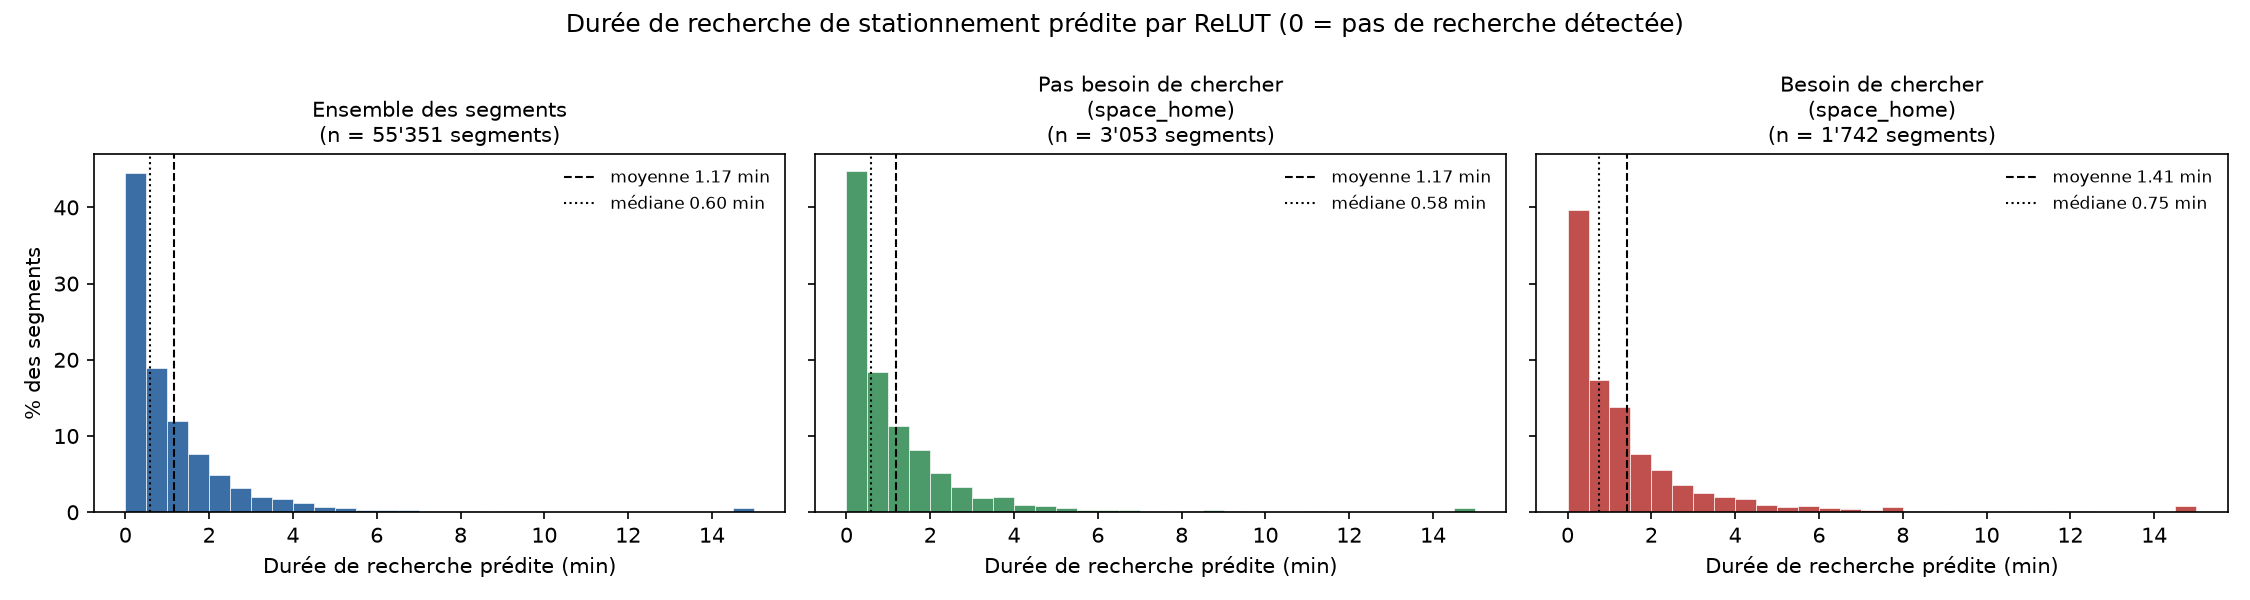

,groupe,n_segments,temps_moyen_min,temps_median_min,n_segments_avec_recherche,part_avec_recherche,temps_moyen_min_si_recherche,temps_median_min_si_recherche
0,Ensemble,55351,1.17,0.60,53268,0.96,1.22,0.67
1,Pas besoin de chercher,3053,1.17,0.58,2924,0.96,1.22,0.65
2,Besoin de chercher,1742,1.41,0.75,1687,0.97,1.46,0.78


,variable,groupe,n_segments,temps_moyen_min,temps_median_min,n_segments_avec_recherche,part_avec_recherche,temps_moyen_min_si_recherche,temps_median_min_si_recherche
0,space_home,Place dédiée,47188,1.16,0.60,45417,0.96,1.20,0.67
1,space_home,"Pas de place dédiée, pas besoin de cruise",3053,1.17,0.58,2924,0.96,1.22,0.65
2,space_home,Aucun,3305,1.26,0.63,3178,0.96,1.31,0.67
3,space_home,"Pas de place dédiée, besoin de cruise",1742,1.41,0.75,1687,0.97,1.46,0.78
4,space_home,non renseigné / absent du questionnaire,63,0.70,0.25,62,0.98,0.71,0.25


In [14]:
display(Image(filename=result["summary"]["outputs"]["histograms"]))
display(result["stats"].round(2))
if result["by_category"] is not None:
    display(result["by_category"].round(2))

## Distances de recherche prédites

Distance = somme des distances entre waypoints consécutifs, du point de bascule jusqu'à la fin du segment (mêmes panneaux que les durées : ensemble, puis groupes de stationnement déclaré) ; 0 si aucune recherche n'est détectée. Les distances au-delà du 99ᵉ percentile des segments avec recherche sont regroupées dans la dernière classe. Tableau : `reports/32_search_distance_stats.csv`.

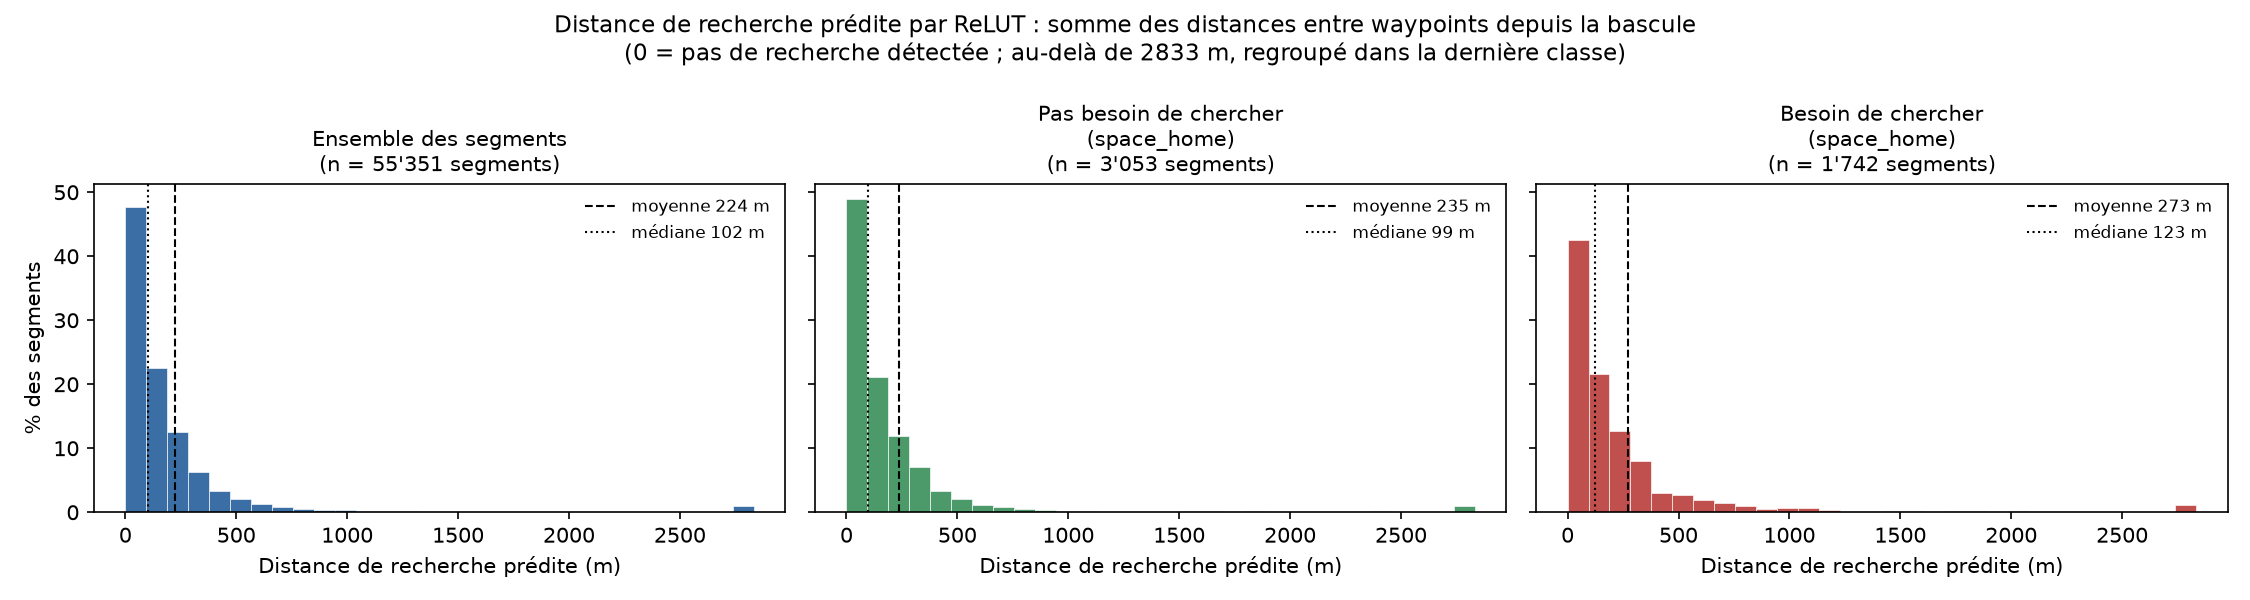

,groupe,n_segments,distance_moyenne_m,distance_mediane_m,n_segments_avec_recherche,distance_moyenne_m_si_recherche,distance_mediane_m_si_recherche,distance_q90_m_si_recherche
0,Ensemble,55351,223.8,102.0,53268,232.5,108.2,406.3
1,Pas besoin de chercher,3053,235.4,98.9,2924,245.8,105.7,411.3
2,Besoin de chercher,1742,273.2,123.1,1687,282.1,128.5,553.5


In [15]:
display(Image(filename=result["summary"]["outputs"]["distance_histograms"]))
result["distance_stats"].round(1)

## Part des legs au-delà de seuils, par stationnement déclaré

Pour chaque catégorie de `space_home` et de `space_work` (plus « Ensemble »), part des legs évaluées dont la durée (resp. la distance) de recherche prédite **dépasse strictement** chaque seuil ; une leg sans recherche compte pour 0 (le seuil 0 donne donc la part de legs avec recherche). Une colonne par seuil, réglable ci-dessous. Tables enregistrées sous `reports/32_part_au_dela_seuils_<durée|distance>_<variable>.csv`.

In [16]:
from parking_search_prediction.relut_detection import threshold_share_table

DURATION_THRESHOLDS_S = [0, 30, 60, 120, 300, 600]
DISTANCE_THRESHOLDS_M = [0, 100, 200, 500, 1000, 2000]

share_tables = {}
for variable in ("space_home", "space_work"):
    for measure, thresholds in (("duration", DURATION_THRESHOLDS_S), ("distance", DISTANCE_THRESHOLDS_M)):
        table = threshold_share_table(config, variable, measure, thresholds)
        share_tables[(variable, measure)] = table
        share_columns = [c for c in table.columns if c.startswith(">")]
        print(f"{variable} — {'durée' if measure == 'duration' else 'distance'} de recherche")
        display(table.style.format({c: "{:.1%}" for c in share_columns}).hide(axis="index"))

space_home — durée de recherche


space_home,n_legs,> 0 s,> 30 s,> 60 s,> 120 s,> 300 s,> 600 s
Ensemble,55026,86.5%,53.8%,35.5%,16.5%,3.0%,0.9%
Place dédiée,46917,86.3%,53.6%,35.2%,16.2%,2.9%,0.9%
Aucun,3279,88.3%,55.5%,36.8%,18.3%,3.7%,1.0%
"Pas de place dédiée, pas besoin de cruise",3039,85.6%,54.0%,35.9%,17.0%,3.1%,0.9%
"Pas de place dédiée, besoin de cruise",1728,90.2%,58.7%,41.4%,20.9%,4.8%,1.3%
non renseigné,63,77.8%,34.9%,23.8%,11.1%,0.0%,0.0%


space_home — distance de recherche


space_home,n_legs,> 0 m,> 100 m,> 200 m,> 500 m,> 1000 m,> 2000 m
Ensemble,55026,86.5%,50.6%,27.6%,6.8%,2.4%,1.3%
Place dédiée,46917,86.4%,50.2%,27.1%,6.5%,2.3%,1.2%
Aucun,3279,88.2%,54.6%,31.8%,8.8%,3.0%,1.5%
"Pas de place dédiée, pas besoin de cruise",3039,85.6%,49.8%,28.2%,6.8%,2.6%,1.4%
"Pas de place dédiée, besoin de cruise",1728,90.2%,55.8%,33.9%,11.2%,4.2%,1.7%
non renseigné,63,77.8%,36.5%,19.0%,1.6%,0.0%,0.0%


space_work — durée de recherche


space_work,n_legs,> 0 s,> 30 s,> 60 s,> 120 s,> 300 s,> 600 s
Ensemble,55026,86.5%,53.8%,35.5%,16.5%,3.0%,0.9%
non renseigné,35347,86.5%,53.7%,35.1%,16.4%,3.0%,0.9%
"Pas de place dédiée, pas besoin de cruise",13030,86.1%,54.4%,36.3%,16.6%,3.0%,1.0%
"Pas de place dédiée, besoin de cruise",4356,86.7%,53.2%,36.5%,17.6%,3.3%,0.8%
Place dédiée,2293,88.1%,54.3%,35.4%,16.8%,2.7%,0.8%


space_work — distance de recherche


space_work,n_legs,> 0 m,> 100 m,> 200 m,> 500 m,> 1000 m,> 2000 m
Ensemble,55026,86.5%,50.6%,27.6%,6.8%,2.4%,1.3%
non renseigné,35347,86.5%,50.5%,27.7%,6.8%,2.4%,1.3%
"Pas de place dédiée, pas besoin de cruise",13030,86.2%,50.3%,27.1%,6.9%,2.6%,1.4%
"Pas de place dédiée, besoin de cruise",4356,86.8%,51.9%,28.2%,7.3%,2.5%,1.2%
Place dédiée,2293,88.1%,51.0%,27.7%,6.1%,2.0%,1.0%


## Part des legs au-delà d'un seuil, par stationnement déclaré

Pour chaque catégorie de `space_home` et de `space_work` : part des legs évaluées dont la **durée** (minutes) ou la **distance** (mètres) de recherche prédite atteint chaque seuil. Une colonne par seuil ; les legs sans recherche comptent pour 0. Comptage par leg, non pondéré. Tables enregistrées sous `reports/32_part_legs_<durée|distance>_par_<variable>.csv`.

In [17]:
from parking_search_prediction.relut_detection import share_above_thresholds

DURATION_THRESHOLDS_MIN = [0.5, 1, 2, 3, 5, 10]
DISTANCE_THRESHOLDS_M = [100, 200, 500, 1000, 2000]
THRESHOLD_VARIABLES = ["space_home", "space_work"]

sample_id = result["summary"]["relut_by_leg"]["run_id"] if result["summary"]["relut_by_leg"]["sample"] else None
for variable in THRESHOLD_VARIABLES:
    for quantity, thresholds in (("duration", DURATION_THRESHOLDS_MIN), ("distance", DISTANCE_THRESHOLDS_M)):
        table = share_above_thresholds(config, variable, quantity, thresholds, sample_run_id=sample_id)
        share_columns = [c for c in table.columns if c.startswith("≥")]
        print(f"{variable} — {'durée' if quantity == 'duration' else 'distance'} de recherche prédite")
        display(table.style.format({c: "{:.1%}" for c in share_columns}).hide(axis="index"))

space_home — durée de recherche prédite


space_home,n_legs,≥ 0.5 min,≥ 1 min,≥ 2 min,≥ 3 min,≥ 5 min,≥ 10 min
toutes les legs,55026,55.5%,36.5%,16.8%,8.8%,3.1%,0.9%
Aucun,3279,57.5%,37.6%,18.4%,10.2%,3.7%,1.0%
"Pas de place dédiée, besoin de cruise",1728,60.2%,42.7%,21.1%,12.1%,4.8%,1.3%
"Pas de place dédiée, pas besoin de cruise",3039,55.4%,36.9%,17.3%,8.8%,3.1%,0.9%
Place dédiée,46917,55.2%,36.2%,16.6%,8.5%,3.0%,0.9%
non renseigné,63,36.5%,23.8%,11.1%,6.3%,0.0%,0.0%


space_home — distance de recherche prédite


space_home,n_legs,≥ 100 m,≥ 200 m,≥ 500 m,≥ 1000 m,≥ 2000 m
toutes les legs,55026,50.6%,27.6%,6.8%,2.4%,1.3%
Aucun,3279,54.6%,31.8%,8.8%,3.0%,1.5%
"Pas de place dédiée, besoin de cruise",1728,55.8%,33.9%,11.2%,4.2%,1.7%
"Pas de place dédiée, pas besoin de cruise",3039,49.8%,28.2%,6.8%,2.6%,1.4%
Place dédiée,46917,50.2%,27.1%,6.5%,2.3%,1.2%
non renseigné,63,36.5%,19.0%,1.6%,0.0%,0.0%


space_work — durée de recherche prédite


space_work,n_legs,≥ 0.5 min,≥ 1 min,≥ 2 min,≥ 3 min,≥ 5 min,≥ 10 min
toutes les legs,55026,55.5%,36.5%,16.8%,8.8%,3.1%,0.9%
"Pas de place dédiée, besoin de cruise",4356,55.3%,37.4%,18.0%,9.2%,3.4%,0.8%
"Pas de place dédiée, pas besoin de cruise",13030,56.0%,37.3%,16.9%,8.9%,3.1%,1.0%
Place dédiée,2293,55.8%,36.4%,17.1%,9.3%,2.8%,0.8%
non renseigné,35347,55.3%,36.1%,16.7%,8.6%,3.0%,0.9%


space_work — distance de recherche prédite


space_work,n_legs,≥ 100 m,≥ 200 m,≥ 500 m,≥ 1000 m,≥ 2000 m
toutes les legs,55026,50.6%,27.6%,6.8%,2.4%,1.3%
"Pas de place dédiée, besoin de cruise",4356,51.9%,28.2%,7.3%,2.5%,1.2%
"Pas de place dédiée, pas besoin de cruise",13030,50.3%,27.1%,6.9%,2.6%,1.4%
Place dédiée,2293,51.0%,27.7%,6.1%,2.0%,1.0%
non renseigné,35347,50.5%,27.7%,6.8%,2.4%,1.3%


In [27]:
table = threshold_share_table(config, "space_work", "distance", DISTANCE_THRESHOLDS_M)
share_columns = [c for c in table.columns if c.startswith(">")]
merge = ["Place dédiée", "Pas de place dédiée, pas besoin de cruise"]

part = table[table["space_work"].isin(merge)]
weights = part["n_legs"]
merged = {"space_work": "Pas besoin de chercher (fusion)", "n_legs": int(weights.sum()),
          **{c: (part[c] * weights).sum() / weights.sum() for c in share_columns}}
pd.concat([table, pd.DataFrame([merged])], ignore_index=True).style.format({c: "{:.1%}" for c in share_columns})

,space_work,n_legs,> 100 m,> 200 m,> 500 m,> 1000 m,> 2000 m
0,Ensemble,55026,50.6%,27.6%,6.8%,2.4%,1.3%
1,non renseigné,35347,50.5%,27.7%,6.8%,2.4%,1.3%
2,"Pas de place dédiée, pas besoin de cruise",13030,50.3%,27.1%,6.9%,2.6%,1.4%
3,"Pas de place dédiée, besoin de cruise",4356,51.9%,28.2%,7.3%,2.5%,1.2%
4,Place dédiée,2293,51.0%,27.7%,6.1%,2.0%,1.0%
5,Pas besoin de chercher (fusion),15323,50.4%,27.2%,6.7%,2.5%,1.3%


## Courbes de probabilité — échantillon générique

`N_GENERIC_SAMPLE` segments tirés au hasard (graine `RANDOM_SEED`). Rouge pastel : partie prédite en cruising, à partir du point de bascule (trait pointillé vertical). Ligne pointillée horizontale : seuil de probabilité utilisé, indiqué en légende (avec `P_SEARCH = "auto"`, il dépend de l'échantillonnage médian du segment). La bascule peut être plus tardive que le premier dépassement du seuil si la recherche est plafonnée à `MAX_SEARCH_DURATION_MINUTES`. Liste des segments : `reports/32_generic_sample_segments.csv` ; mêmes segments sur la carte `32_generic_sample.html`.

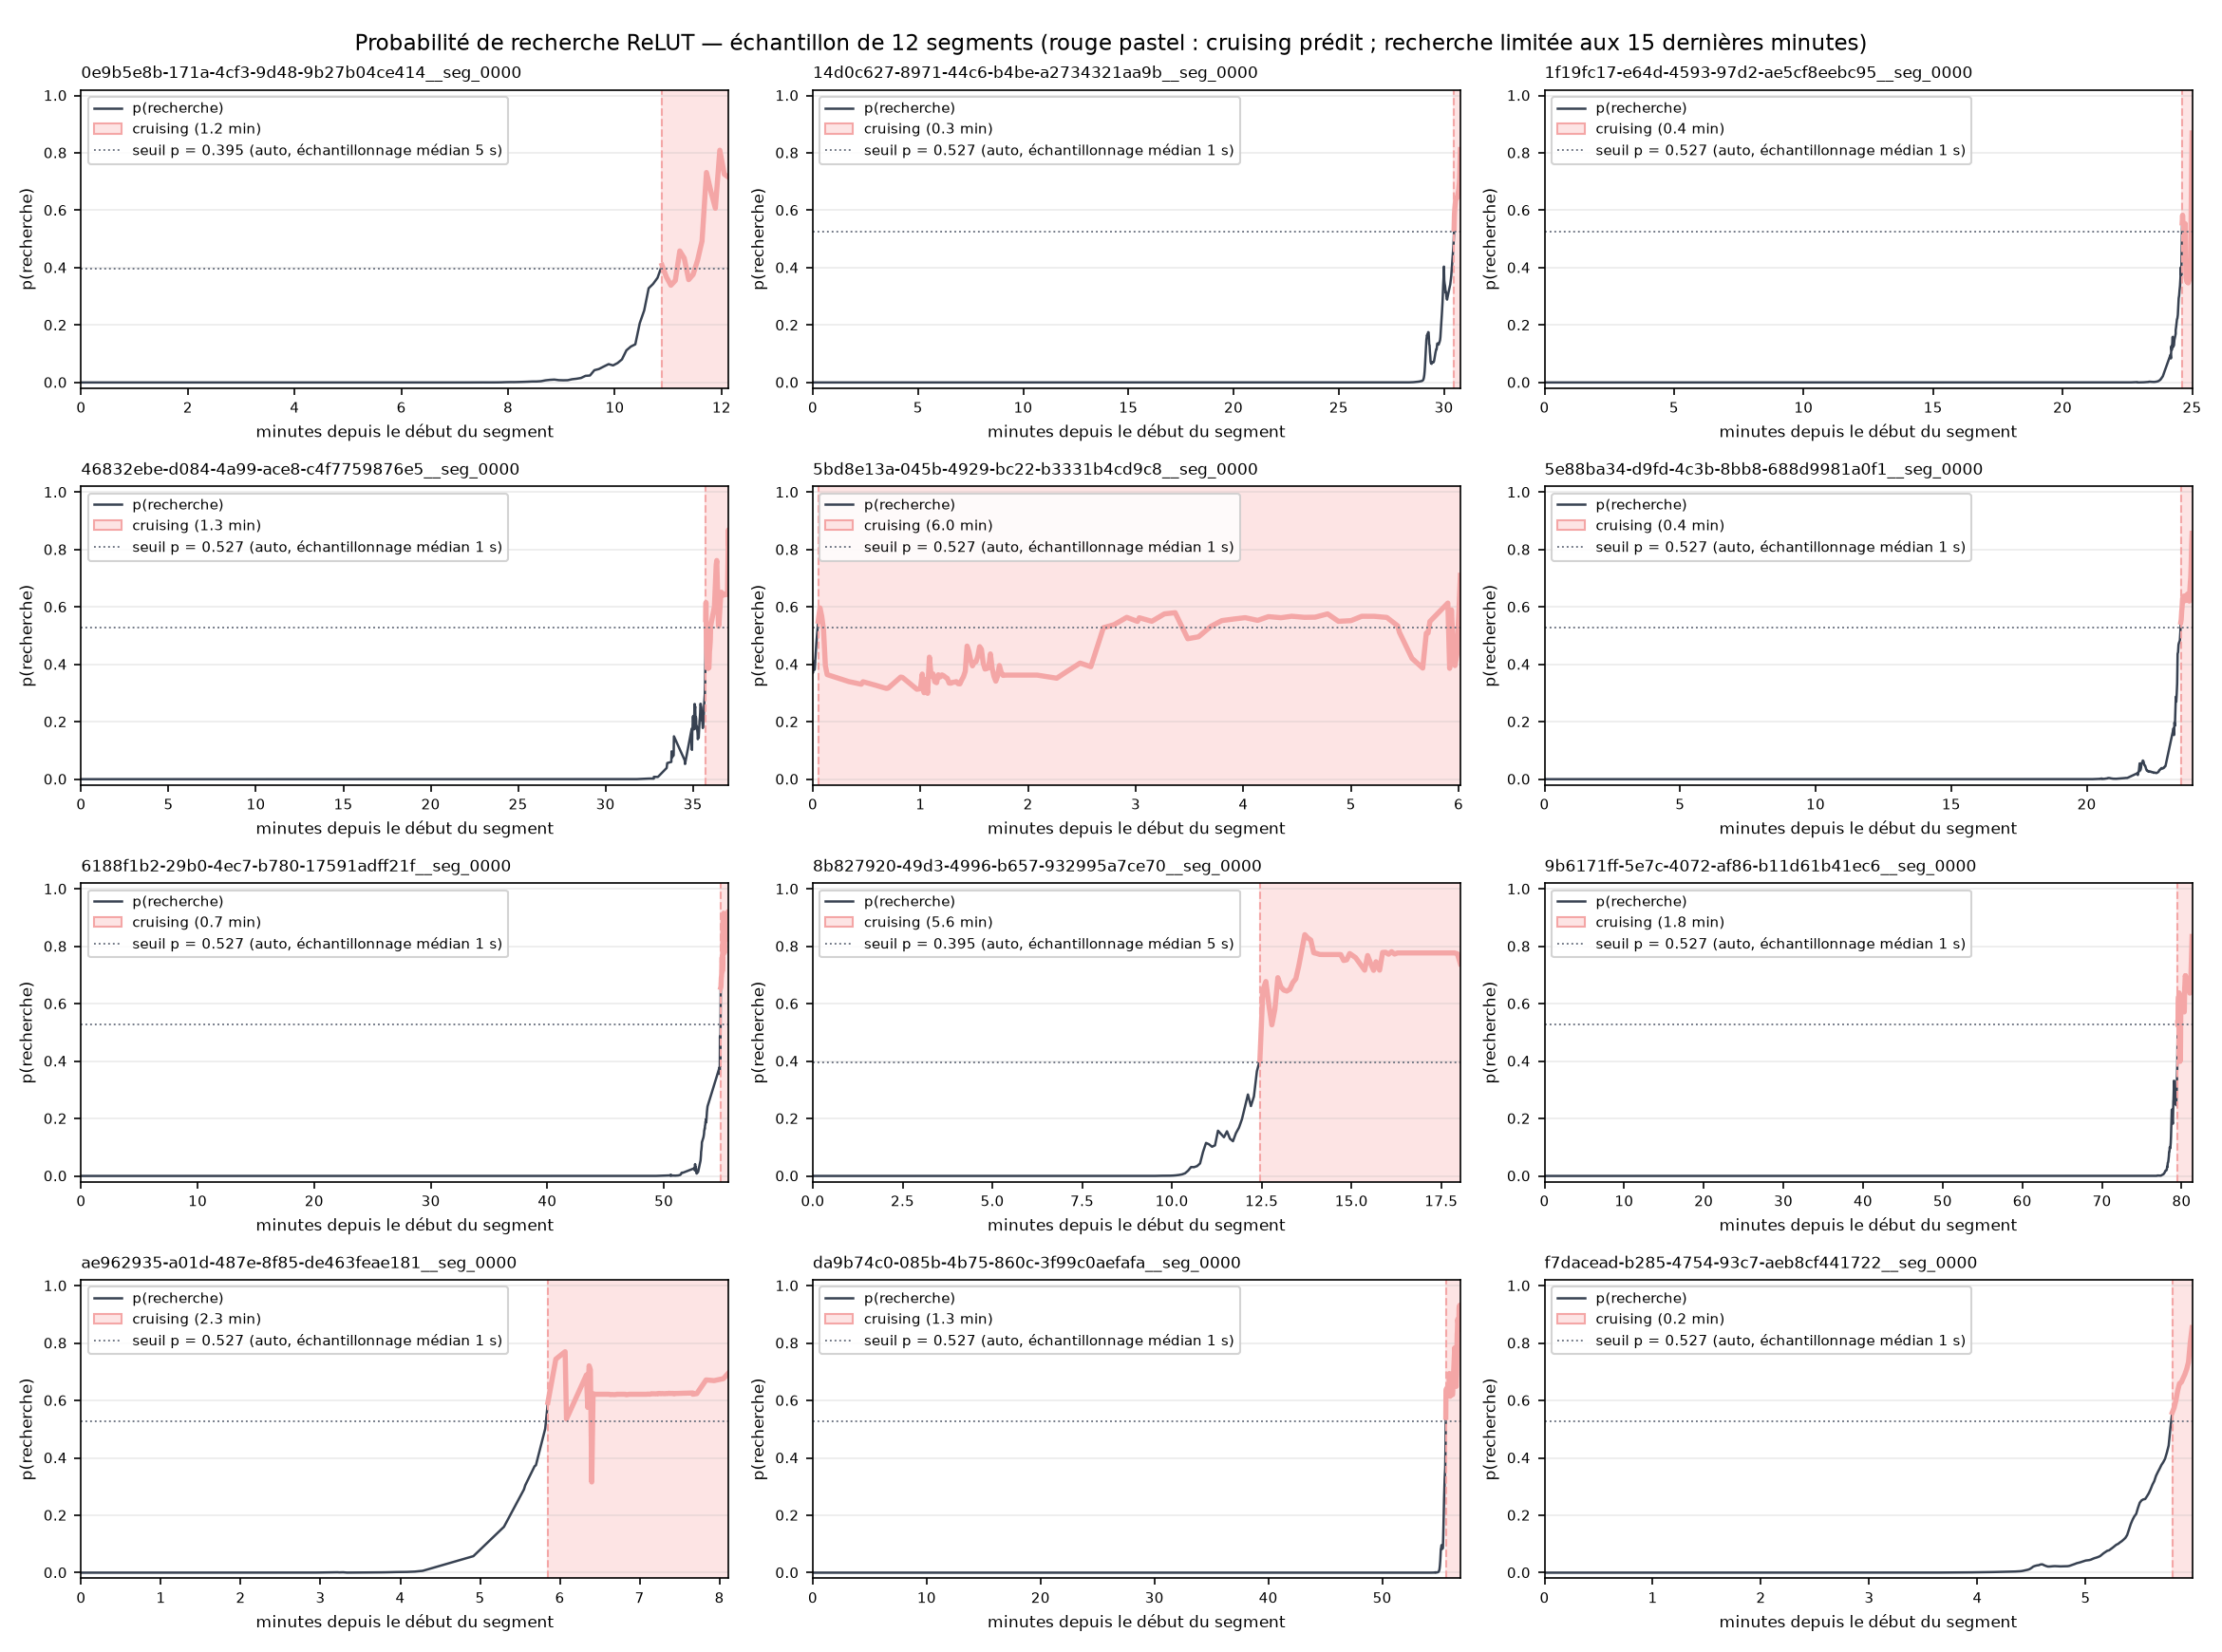

In [18]:
if result["summary"]["outputs"]["probability_curves"]:
    display(Image(filename=result["summary"]["outputs"]["probability_curves"]))

## Cartes

Traces en bleu (conduite) et rouge (recherche prédite), drapeau au début de la recherche. Les cartes s'ouvrent dans le navigateur.

In [19]:
for name, path in result["summary"]["outputs"]["maps"].items():
    if path:
        display(HTML(f'<p><a href="{Path(path).as_uri()}" target="_blank">{Path(path).name}</a></p>'))

## Table par leg et vue d'assemblage

`relut_by_leg` contient **toutes les legs** (clé `leg_id`). Pour chaque leg voiture, le **dernier segment** est retenu, sans repli sur un segment antérieur. `relut_status` dit s'il a été prédit (`evaluated`) ou pourquoi il ne l'a pas été (`not_car_leg`, `no_car_waypoints`, `outside_study_area`, `no_segment`, `last_segment_rejected`, `last_segment_loop`, `not_sampled`). Règle de la collection : **0 = évalué sans recherche, NaN = non évalué**. Distances : `relut_search_distance_m` le long de la trace depuis la bascule, `relut_straight_line_distance_m` à vol d'oiseau entre la bascule et le stationnement.

`load_leg_table` assemble `legs_enriched` (trip, motif, moment, questionnaire, marche après la voiture) et les tables demandées par jointure sur `leg_id`. Dictionnaire généré : `legs/_dictionary.csv` ; provenance : `legs/_manifest.json`.

In [20]:
info = result["summary"]["relut_by_leg"]
if info:
    display(pd.Series(info["status_counts"], name="relut_status"))
    legs = load_leg_table(config, ["relut_by_leg"], sample_run_id=info["run_id"] if info["sample"] else None)
    car = legs[legs["relut_status"].ne("not_car_leg")]
    display(car.groupby("relut_status", dropna=False)[["relut_search_duration_s", "relut_search_distance_m"]].agg(["count", "mean", "median"]).round(1))
    shown = [c for c in ["leg_id", "purpose_agg", "space_home", "relut_search_duration_s", "relut_search_distance_m",
                         "relut_straight_line_distance_m"] if c in legs.columns]
    display(legs.loc[legs["relut_status"].eq("evaluated"), shown].head())

not_car_leg              465516
outside_study_area       116215
evaluated                 55026
excluded_by_corpus        21016
no_car_waypoints           1370
last_segment_rejected        57
Name: relut_status, dtype: int64

[legs] relut_by_leg : 659200 lignes — run 20261112T180014_all — 2026-11-12T17:00:16+00:00


relut_search_duration_s               \
                                        count  mean median   
relut_status                                                 
evaluated                               55026  69.6   36.0   
excluded_by_corpus                          0   NaN    NaN   
last_segment_rejected                       0   NaN    NaN   
no_car_waypoints                            0   NaN    NaN   
outside_study_area                          0   NaN    NaN   

                      relut_search_distance_m                
                                        count   mean median  
relut_status                                                 
evaluated                               55026  223.9  102.0  
excluded_by_corpus                          0    NaN    NaN  
last_segment_rejected                       0    NaN    NaN  
no_car_waypoints                            0    NaN    NaN  
outside_study_area                          0    NaN    NaN

,leg_id,purpose_agg,space_home,relut_search_duration_s,relut_search_distance_m,relut_straight_line_distance_m
478,bcba0f61-db50-4354-a3ec-6a1d956e6b50,Achats et services,Aucun,0.0,0.000000,0.000000
479,eb07f932-c53c-4ce2-812c-51d997e311f6,Loisirs,Aucun,4.0,28.766323,28.597713
480,2727511b-697a-4d97-a85b-b4f05847957d,Achats et services,Aucun,9.0,52.303214,39.240014
916,e1118f66-5b72-43f3-a1d5-57703b18dc27,Loisirs,Place dédiée,50.0,16.075613,13.622686
917,822f45b5-7880-4012-997b-38adbea3fad7,Travail,Place dédiée,0.0,0.000000,0.000000
